$\textbf{3.3 ЛР 3. Интерполяция функций. Полиномы Лагранжа, Ньютона.}$

Пусть есть прибор, который в дискретные моменты времени выдаёт сигнал по закону $$f(t)$$ Допустим, наблюдатель зарегистрировал пять отсчётов в моменты времени $$t_i$$ Задачей наблюдателя (который не знает закона выдачи сигнала) является получение приближённого значения функции на отрезке $$[0,1]$$ в любой момент времени. Выберите функцию $$f(t)$$ и моменты времени $$t_i$$, номер которых совпадает с номером вашего компьютера:

**7.**
$$
f(t)=\sin\frac{\pi t}{3}, \qquad t_i=\frac{i}{5}, \quad i=0,1,2,3,4.
$$

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [8]:
def lagrange(x_nodes, y_nodes, x_eval):

    x_nodes = np.asarray(x_nodes, dtype=float)
    y_nodes = np.asarray(y_nodes, dtype=float)
    x_eval = np.atleast_1d(np.asarray(x_eval, dtype=float))

    n = len(x_nodes)

    P_n = np.zeros_like(x_eval, dtype=float)

    for k in range(n):
        L = np.ones_like(x_eval, dtype=float)

        for j in range(n):
            if j != k:
                L *= (x_eval - x_nodes[j]) / (x_nodes[k] - x_nodes[j])

        P_n += y_nodes[k] * L

    return P_n

$$
A_0 = y_0
$$

$$
A_1 = \frac{y_1 - A_0}{x_1 - x_0}
$$

$$
A_2 = \frac{y_2 - A_0 - A_1(x_2 - x_0)}
{(x_2 - x_0)(x_2 - x_1)}
$$

$$
A_3 = \frac{y_3 - A_0 - A_1(x_3 - x_0) - A_2(x_3 - x_0)(x_3 - x_1)}
{(x_3 - x_0)(x_3 - x_1)(x_3 - x_2)}
$$

$$
A_4 = \frac{y_4 - A_0 - A_1(x_4 - x_0) - A_2(x_4 - x_0)(x_4 - x_1) - A_3(x_4 - x_0)(x_4 - x_1)(x_4 - x_2)}
{(x_4 - x_0)(x_4 - x_1)(x_4 - x_2)(x_4 - x_3)}
$$

In [9]:
from math import prod

def newton(x_nodes, y_nodes, x_eval):
    x_nodes = np.asarray(x_nodes, dtype=float)
    y_nodes = np.asarray(y_nodes, dtype=float)
    x_eval = np.atleast_1d(np.asarray(x_eval, dtype=float))

    n = len(x_nodes)
    A = np.zeros(n, dtype=float)

    # первый коэффициент
    A[0] = y_nodes[0]

    # последовательно находим остальные коэффициенты
    for i in range(1, n):
        part1 = sum(A[k] * prod(x_nodes[i] - x_nodes[j] for j in range(k)) for k in range(i))

        part2 = prod(x_nodes[i] - x_nodes[j] for j in range(i))

        A[i] = (y_nodes[i] - part1) / part2

    p = np.array([
        sum(A[i] * prod(x - x_nodes[j] for j in range(i)) for i in range(n)) for x in x_eval ], dtype=float)

    return p, A

In [10]:
def lin_interp(x_nodes, y_nodes, x_eval):
    # Кусочно-линейная интерполяция
    x_nodes = np.asarray(x_nodes, dtype=float)
    y_nodes = np.asarray(y_nodes, dtype=float)
    x_eval = np.asarray(x_eval, dtype=float)

    return np.interp(
        np.clip(x_eval, x_nodes[0], x_nodes[-1]),
        x_nodes, y_nodes
    )

In [11]:
def chebyshev(a, b, n):

    k = np.arange(n)
    x = (a + b) / 2 + (b - a) / 2 * np.cos((2 * k + 1) * np.pi / (2 * n))
    return np.sort(x)


In [12]:
def setup_axes(ax, title, xlabel="x", ylabel="y"):
    ax.set_title(title, fontsize=13)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.35)

    ax.axhline(0, color="black", linewidth=2.5)
    ax.axvline(0, color="black", linewidth=2.5)


def plot_func(f, a, b, title, label, color="blue", n=2000, ylabel="y"):
    x = np.linspace(a, b, n)
    y = f(x)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(x, y, color=color, linewidth=2, label=label)
    setup_axes(ax, title, xlabel="x", ylabel=ylabel)
    ax.legend()
    plt.show()

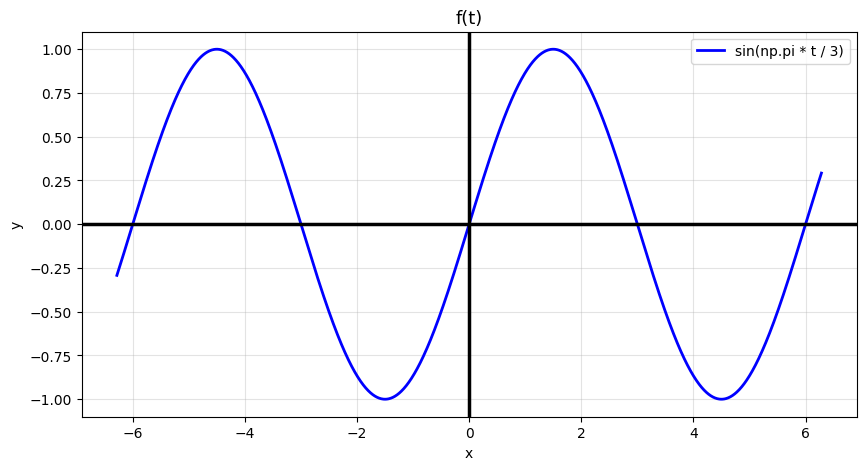

In [13]:
f = lambda t: np.sin(np.pi * t / 3)

plot_func(f, -2*np.pi, 2*np.pi,"f(t)","sin(np.pi * t / 3)")

In [14]:
t_nodes = np.arange(5) / 5
y_nodes = f(t_nodes)
t_nodes

array([0. , 0.2, 0.4, 0.6, 0.8])

In [15]:
grid = np.linspace(t_nodes[0], t_nodes[-1], 2000)
f_grid = f(grid)
f_grid

array([0.00000000e+00, 4.19088552e-04, 8.38177031e-04, ...,
       7.42583715e-01, 7.42864335e-01, 7.43144825e-01], shape=(2000,))

In [16]:
lin_grid = lin_interp(t_nodes, y_nodes, grid)
lin_grid

array([0.00000000e+00, 4.16031397e-04, 8.32062795e-04, ...,
       7.42523076e-01, 7.42833951e-01, 7.43144825e-01], shape=(2000,))

In [18]:
lag_grid = lagrange(t_nodes, y_nodes, grid)
lag_grid

array([0.00000000e+00, 4.18938681e-04, 8.37878545e-04, ...,
       7.42583995e-01, 7.42864476e-01, 7.43144825e-01], shape=(2000,))

In [20]:
newton_coef, newton_grid = newton(t_nodes, y_nodes, grid)
newton_grid

array([ 0.        ,  1.03955845, -0.11358423, -0.18103343,  0.02023207])

In [21]:
lin_at_nodes = lin_interp(t_nodes, y_nodes, t_nodes)
lin_at_nodes

array([0.        , 0.20791169, 0.40673664, 0.58778525, 0.74314483])

In [22]:
lag_at_nodes = lagrange(t_nodes, y_nodes, t_nodes)
lag_at_nodes

array([0.        , 0.20791169, 0.40673664, 0.58778525, 0.74314483])

In [23]:
newt_at_nodes = newton(t_nodes, newton_coef, t_nodes)
newt_at_nodes

(array([0.        , 0.00041894, 0.00083788, 0.00125682, 0.00167576]),
 array([ 0.00000000e+00,  2.09469341e-03,  1.47806169e-08, -1.64457226e-09,
         3.24340209e-13]))

In [24]:
lin_err = np.abs(f_grid - lin_grid)
lin_err

array([0.00000000e+00, 3.05715516e-06, 6.11423671e-06, ...,
       6.06382173e-05, 3.03843452e-05, 0.00000000e+00], shape=(2000,))

In [25]:
lag_err = np.abs(f_grid - lag_grid)
lag_err

array([0.00000000e+00, 1.49871125e-07, 2.98486194e-07, ...,
       2.80483912e-07, 1.40823300e-07, 0.00000000e+00], shape=(2000,))

In [27]:
newton_grid, newton_coef = newton(t_nodes, y_nodes, grid)
newt_err = np.abs(f_grid - newton_grid)
newt_err

array([0.00000000e+00, 1.49871125e-07, 2.98486194e-07, ...,
       2.80483912e-07, 1.40823300e-07, 0.00000000e+00], shape=(2000,))

In [28]:
print("\nМаксимальные ошибки на [0, 0.8]:")
print(f"Линейная интерполяция: {np.max(lin_err):.10f}")
print(f"Полином Лагранжа:      {np.max(lag_err):.10f}")
print(f"Полином Ньютона:       {np.max(newt_err):.10f}")


Максимальные ошибки на [0, 0.8]:
Линейная интерполяция: 0.0036669434
Полином Лагранжа:      0.0000113346
Полином Ньютона:       0.0000113346


In [29]:
# |R_4(t)| <= M5/5! * |(t-t0)(t-t1)...(t-t4)|, где M5 = max |f^(5)(t)|
# f^(5)(t) = (pi/3)^5 * cos(pi t/3 + 5*pi/2), значит M5 = (pi/3)^5

omega = np.prod(grid[:, None] - t_nodes[None, :], axis=1)
M5 = (np.pi / 3) ** 5
theory_bound = M5 * np.max(np.abs(omega)) / math.factorial(5)

print(f"Теоретическая оценка ошибки полинома степени 4: {theory_bound:.10f}")

Теоретическая оценка ошибки полинома степени 4: 0.0000121952


In [30]:
# значение полинома при t = 2
t_extrap = 2.0
f_2 = f(t_extrap)
p_2 = lagrange(t_nodes, y_nodes, np.array([t_extrap]))[0]
print(f_2, p_2)
f_2 - p_2

0.8660254037844387 0.7906125483579558


np.float64(0.0754128554264829)

In [31]:
print("\nКоэффициенты полинома Ньютона:")
for i, c in enumerate(newton_coef):
    print(f"a{i} = {c:.10f}")


Коэффициенты полинома Ньютона:
a0 = 0.0000000000
a1 = 1.0395584541
a2 = -0.1135842320
a3 = -0.1810334267
a4 = 0.0202320701


In [32]:
def plot_curves(x, curves, title, xlabel="x", ylabel="y", nodes_x=None, nodes_y=None, nodes_label="Узлы"):
    fig, ax = plt.subplots(figsize=(10, 6))

    for y, label, style in curves:
        ax.plot(x, y, style, linewidth=2, label=label)

    if nodes_x is not None and nodes_y is not None:
        ax.scatter(nodes_x, nodes_y, color="red", zorder=5, label=nodes_label)

    setup_axes(ax, title, xlabel=xlabel, ylabel=ylabel)
    ax.legend()
    plt.show()

def print_values_at_points(f, x_nodes, y_nodes, points, name):
    print(f"\n{name}:")
    for x0 in points:
        fx = f(x0)
        px = lagrange(x_nodes, y_nodes, np.array([x0]))[0]
        print(f"x = {x0:.1f}: f(x) = {fx:.10f}, P(x) = {px:.10f}, |ошибка| = {abs(fx - px):.10f}")

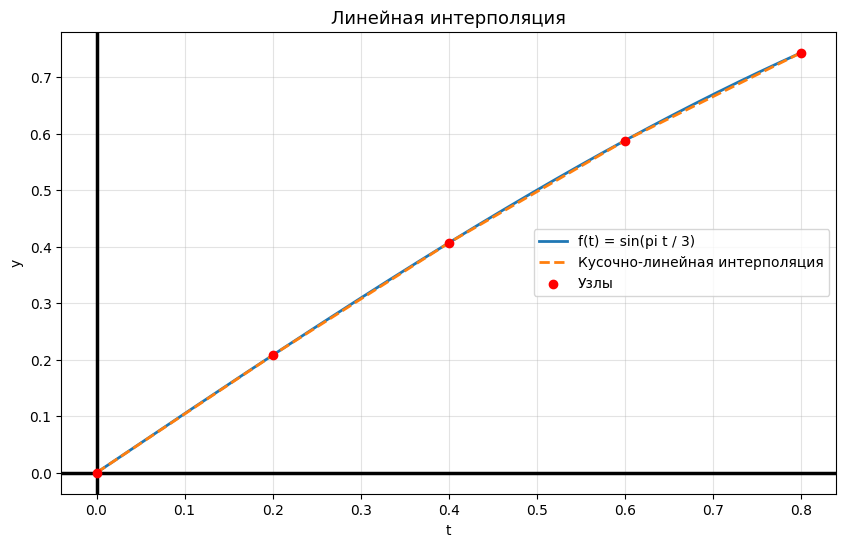

In [33]:
plot_curves(
    grid,
    [
        (f_grid, 'f(t) = sin(pi t / 3)', '-'),
        (lin_grid, 'Кусочно-линейная интерполяция', '--')
    ],
    title='Линейная интерполяция',
    xlabel='t',
    ylabel='y',
    nodes_x=t_nodes,
    nodes_y=y_nodes
    )

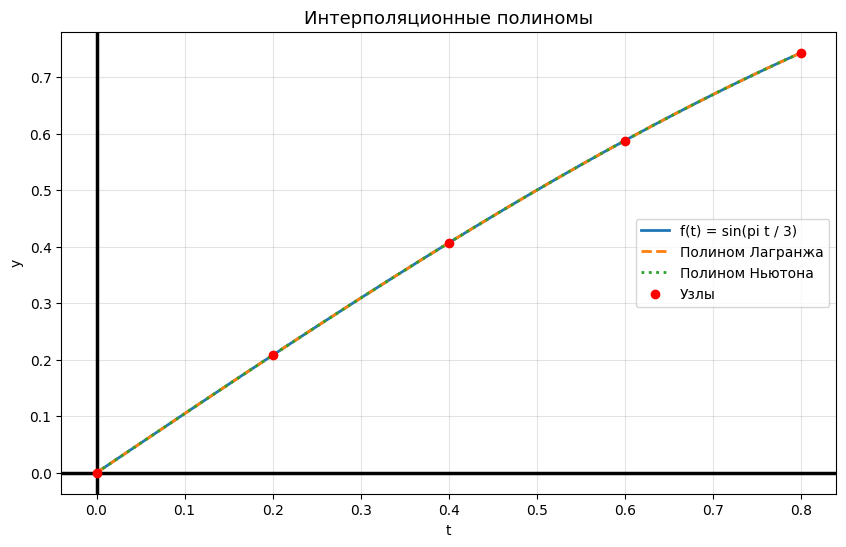

In [ ]:
plot_curves(
    grid,
    [
        (f_grid, 'f(t) = sin(pi t / 3)', '-'),
        (lag_grid, 'Полином Лагранжа', '--'),
        (newton_grid, 'Полином Ньютона', ':')
    ],
    title='Интерполяционные полиномы',
    xlabel='t',
    ylabel='y',
    nodes_x=t_nodes,
    nodes_y=y_nodes
)

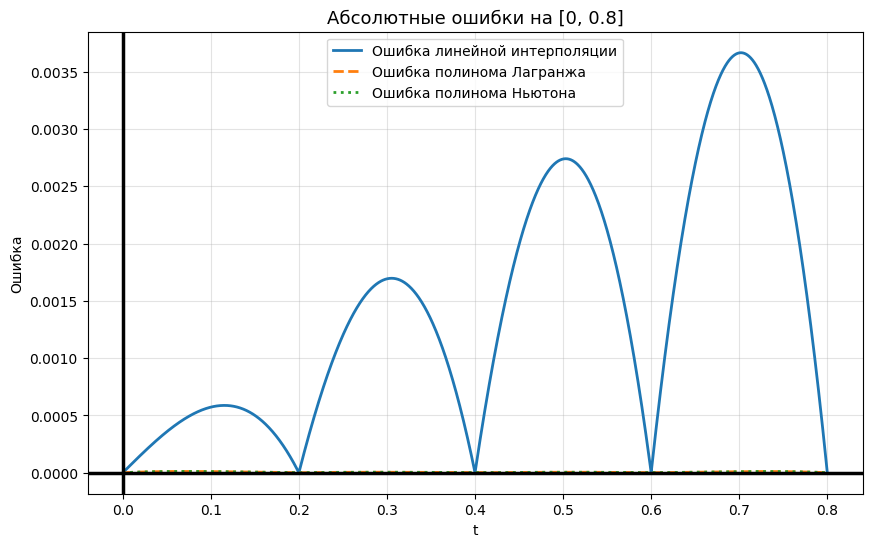

In [34]:
plot_curves(
    grid,
    [
        (lin_err, 'Ошибка линейной интерполяции', '-'),
        (lag_err, 'Ошибка полинома Лагранжа', '--'),
        (newt_err, 'Ошибка полинома Ньютона', ':')
    ],
    title='Абсолютные ошибки на [0, 0.8]',
    xlabel='t',
    ylabel='Ошибка'
)

### 2. Интерполяция функции Рунге

Зададим функцию Рунге

$$
f(x)=\frac{1}{1+25x^2}
$$

на отрезке

$$
[-5,\,5]
$$

в десяти равноотстоящих точках.

Сравним значения функции и интерполяционного полинома при

$$
x=4.5
$$

Построим графики функции и интерполяционного полинома на заданном отрезке и объясним поведение интерполяционного полинома.

Посмотрим, что будет происходить при постепенном увеличении числа узлов интерполяции, и подумаем, как можно избавиться от получившегося эффекта.


Функция Рунге. 10 равноотстоящих узлов:
x = 4.0: f(x) = 0.0024937656, P(x) = -0.0091935408, |ошибка| = 0.0116873064
x = 5.0: f(x) = 0.0015974441, P(x) = 0.0015974441, |ошибка| = 0.0000000000
Максимальная ошибка на [-5, 5] для равноотстоящих узлов: 0.8644586727


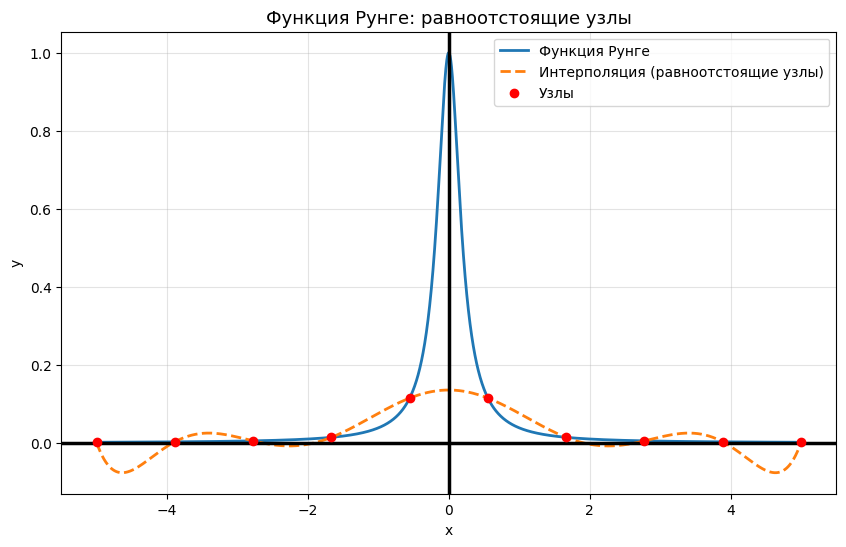

In [36]:
runge = lambda x: 1.0 / (1.0 + 25.0 * x**2)

a, b = -5.0, 5.0
n = 10

grid = np.linspace(a, b, 3000)
runge_grid = runge(grid)

x = np.linspace(a, b, n)
y = runge(x)
P = lagrange(x, y, grid)

print_values_at_points(runge, x, y, [4.0, 5.0], "Функция Рунге. 10 равноотстоящих узлов")
print(f"Максимальная ошибка на [-5, 5] для равноотстоящих узлов: {np.max(np.abs(runge_grid - P)):.10f}")

plot_curves(
    grid,
    [
        (runge_grid, 'Функция Рунге', '-'),
        (P, 'Интерполяция (равноотстоящие узлы)', '--')
    ],
    title='Функция Рунге: равноотстоящие узлы',
    xlabel='x',
    ylabel='y',
    nodes_x=x,
    nodes_y=y
)

In [37]:
print("\nРост ошибки для равноотстоящих узлов:")
for n_test in [6, 10, 14, 18, 20, 30]:
    x_tmp = np.linspace(a, b, n_test)
    y_tmp = runge(x_tmp)
    p_tmp = lagrange(x_tmp, y_tmp, grid)
    err_tmp = np.max(np.abs(runge_grid - p_tmp))
    print(f"n = {n_test:2d}: max error = {err_tmp:.10f}")


Рост ошибки для равноотстоящих узлов:
n =  6: max error = 0.9556851897
n = 10: max error = 0.8644586727
n = 14: max error = 0.7781710519
n = 18: max error = 8.3053204900
n = 20: max error = 27.4778515128
n = 30: max error = 11602.7130384096



Чебышёвские узлы:
x = 4.0: f(x) = 0.0024937656, P(x) = 0.0047740742, |ошибка| = 0.0022803086
x = 5.0: f(x) = 0.0015974441, P(x) = 0.0030751516, |ошибка| = 0.0014777075
Максимальная ошибка на [-5, 5] для узлов Чебышёва: 0.9249754900


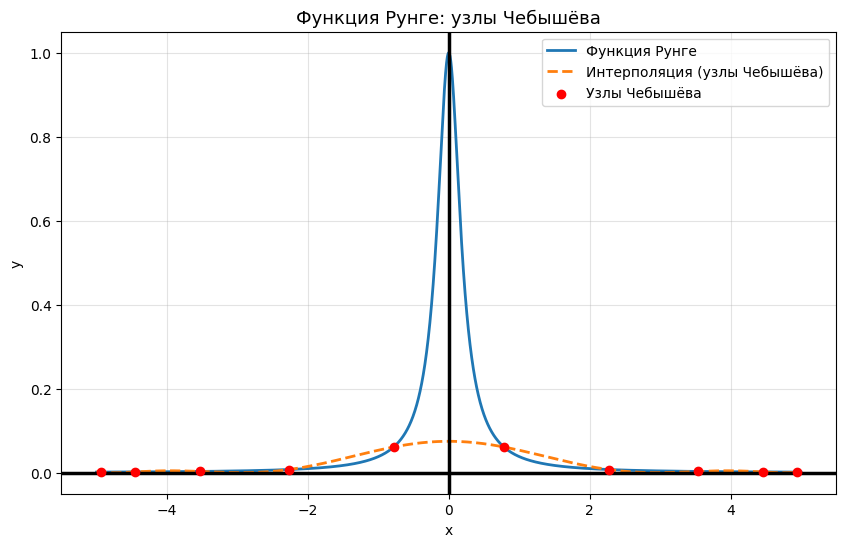

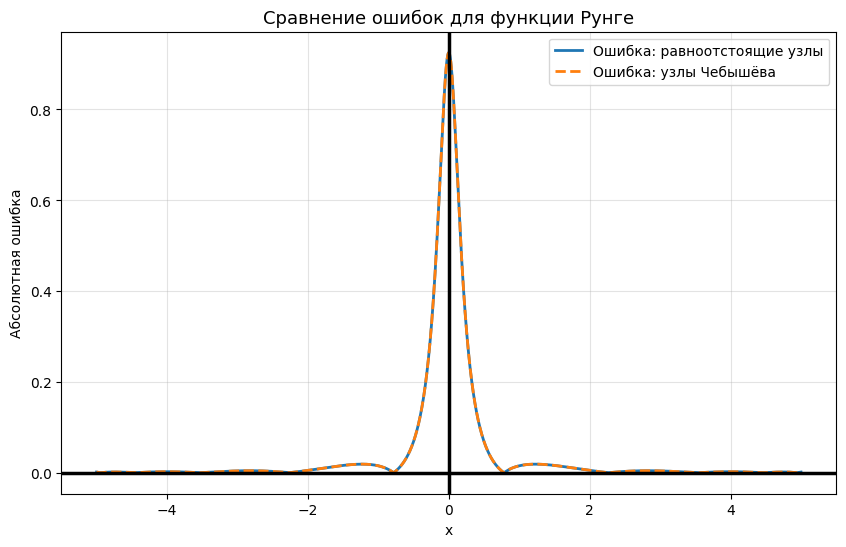

In [38]:
x = chebyshev(a, b, n)
y = runge(x)
P = lagrange(x, y, grid)

print_values_at_points(runge, x, y, [4.0, 5.0], "Чебышёвские узлы")
print(f"Максимальная ошибка на [-5, 5] для узлов Чебышёва: {np.max(np.abs(runge_grid - P)):.10f}")

plot_curves(
    grid,
    [
        (runge_grid, 'Функция Рунге', '-'),
        (P, 'Интерполяция (узлы Чебышёва)', '--')
    ],
    title='Функция Рунге: узлы Чебышёва',
    xlabel='x',
    ylabel='y',
    nodes_x=x,
    nodes_y=y,
    nodes_label='Узлы Чебышёва'
)

plot_curves(
    grid,
    [
        (np.abs(runge_grid - P), 'Ошибка: равноотстоящие узлы', '-'),
        (np.abs(runge_grid - P), 'Ошибка: узлы Чебышёва', '--')
    ],
    title='Сравнение ошибок для функции Рунге',
    xlabel='x',
    ylabel='Абсолютная ошибка'
)

In [39]:
print("\nСравнение max error при росте числа узлов:")
for n_test in [10, 20, 30]:
    x_eq_tmp = np.linspace(a, b, n_test)
    y_eq_tmp = runge(x_eq_tmp)
    p_eq_tmp = lagrange(x_eq_tmp, y_eq_tmp, grid)
    eq_err_tmp = np.max(np.abs(runge_grid - p_eq_tmp))

    x_ch_tmp = chebyshev(a, b, n_test)
    y_ch_tmp = runge(x_ch_tmp)
    p_ch_tmp = lagrange(x_ch_tmp, y_ch_tmp, grid)
    ch_err_tmp = np.max(np.abs(runge_grid - p_ch_tmp))

    print(f"n = {n_test:2d}:  равноотст. = {eq_err_tmp:.10f},   Чебышёв = {ch_err_tmp:.10f}")


Сравнение max error при росте числа узлов:
n = 10:  равноотст. = 0.8644586727,   Чебышёв = 0.9249754900
n = 20:  равноотст. = 27.4778515128,   Чебышёв = 0.7477371703
n = 30:  равноотст. = 11602.7130384096,   Чебышёв = 0.5523673681
